# Aufgabe 1

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

site_code                      str
year                         int64
month                        int64
day                          int64
hour                         int64
minute                       int64
second                       int64
datetime                       str
time_decimal               float64
air_sample_container_id        str
value                      float64
value_unc                  float64
latitude                   float64
longitude                  float64
altitude                   float64
elevation                  float64
intake_height              float64
method                         str
event_number                 int64
instrument                     str
analysis_datetime              str
qcflag                         str
dtype: object

,site_code,year,month,day,hour,minute,second,datetime,time_decimal,air_sample_container_id,...,latitude,longitude,altitude,elevation,intake_height,method,event_number,instrument,analysis_datetime,qcflag
0,MLO,1969,8,20,17,55,0,1969-08-20T17:55:00Z,1969.634922,33-69,...,19.5300,-155.5800,3399.0,3397.0,2.0,N,78808,LR1,1969-09-09T09:02:00,...
1,MLO,1969,8,20,17,55,0,1969-08-20T17:55:00Z,1969.634922,34-69,...,19.5300,-155.5800,3399.0,3397.0,2.0,N,78809,LR1,1969-09-09T09:12:00,C..
2,MLO,1969,8,20,18,30,0,1969-08-20T18:30:00Z,1969.634989,31-69,...,19.5300,-155.5800,3399.0,3397.0,2.0,N,78810,LR1,1969-09-09T08:58:00,M..
3,MLO,1969,8,20,18,30,0,1969-08-20T18:30:00Z,1969.634989,32-69,...,19.5300,-155.5800,3399.0,3397.0,2.0,N,78811,LR1,1969-09-09T09:00:00,M..
4,MLO,1969,8,27,19,15,0,1969-08-27T19:15:00Z,1969.654252,35-69,...,19.5300,-155.5800,3399.0,3397.0,2.0,N,78812,LR1,1969-09-09T08:42:00,M..
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10935,MLO,2024,12,24,19,17,0,2024-12-24T19:17:00Z,2024.980337,2242-99,...,19.5362,-155.5763,3437.0,3397.0,40.0,S,545830,PIC-032,2025-03-20T12:14:29,...
10936,MLO,2024,12,31,19,40,0,2024-12-31T19:40:00Z,2024.999507,1282-99,...,19.5362,-155.5763,3402.0,3397.0,5.0,P,547491,PIC-032,2025-03-21T14:19:50,...
10937,MLO,2024,12,31,19,40,0,2024-12-31T19:40:00Z,2024.999507,5182-99,...,19.5362,-155.5763,3402.0,3397.0,5.0,P,547492,PIC-032,2025-03-21T14:34:17,...
10938,MLO,2024,12,31,19,43,0,2024-12-31T19:43:00Z,2024.999512,2683-99,...,19.5362,-155.5763,3437.0,3397.0,40.0,S,547489,PIC-032,2025-03-21T15:17:33,...


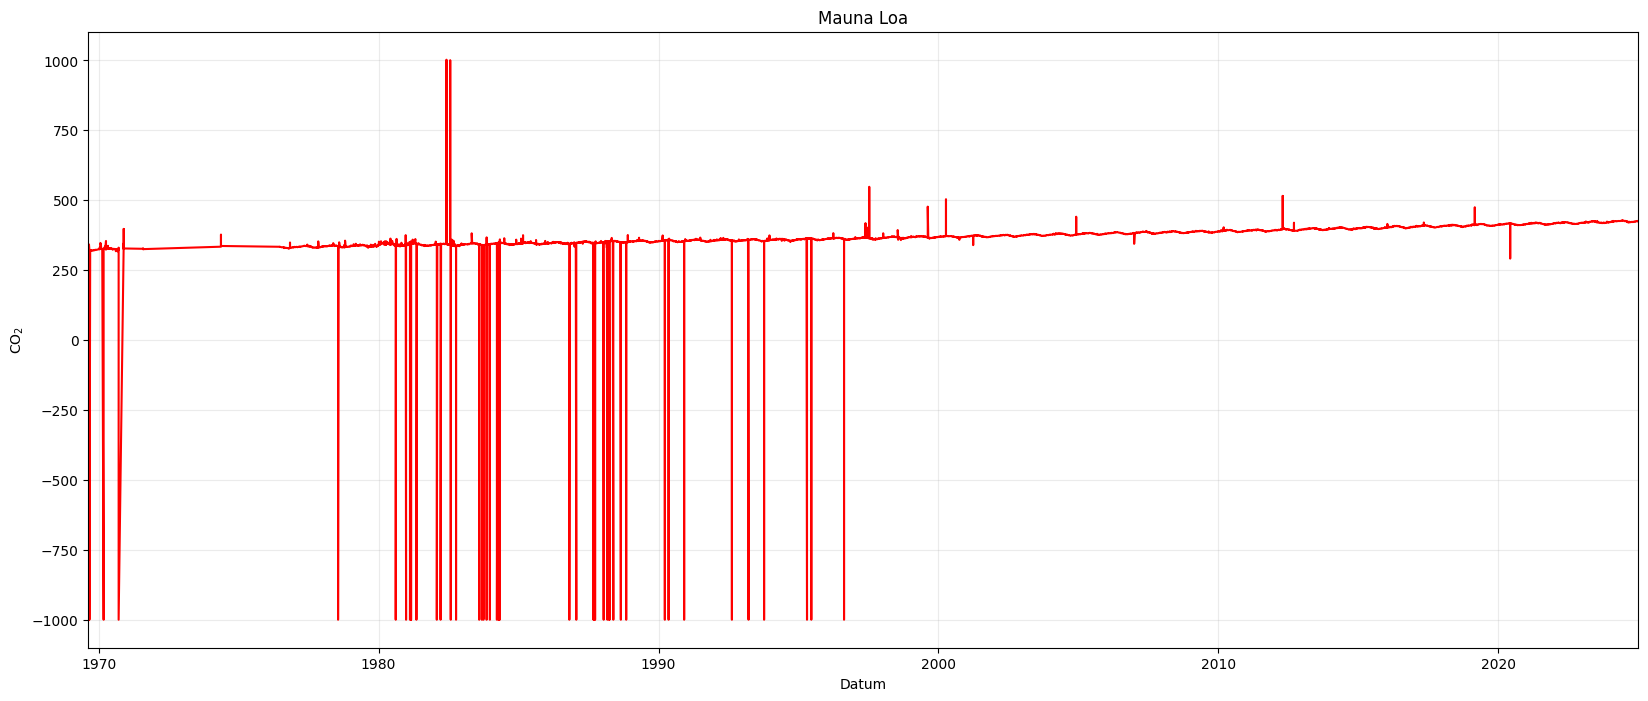

In [2]:
df = pd.read_csv("co2_mlo_surface-flask_1_ccgg_event.txt", sep=r"\s+", comment="#", header=0)

display(df.dtypes)
display(df)

df["datetime"] = pd.to_datetime(df["datetime"])
df = df.set_index("datetime")[["value"]].sort_index()

# df = df.resample("MS").mean().dropna()

plt.figure(figsize=(20, 8))

plt.plot(df["value"], color="red")

plt.title("Mauna Loa")
plt.xlabel("Datum")
plt.ylabel(r"CO$_2$")
plt.grid(alpha=0.25)
plt.margins(x=0)
plt.show()

In [3]:
series = df.index.to_series()
m = series.diff() > pd.Timedelta(days=1)

gaps = pd.DataFrame(
    {
        "start": series[m].shift(1),
        "end": series[m],
    }
)
gaps["length"] = gaps["end"] - gaps["start"]
gaps = gaps.reset_index(drop=True)

print("Lücken der Zeitreihe:")
display(gaps.sort_values(by="length", ascending=False).head(15))

# Zuschneiden der Zeitreihe
df = df.loc[pd.to_datetime("1977-01-01 20:00:00+00:00") :].copy()

Lücken der Zeitreihe:


,start,end,length
29,1971-08-03 20:30:00+00:00,1974-05-15 23:30:00+00:00,1016 days 03:00:00
30,1974-05-15 23:30:00+00:00,1976-06-18 20:00:00+00:00,764 days 20:30:00
28,1970-11-24 00:00:00+00:00,1971-08-03 20:30:00+00:00,252 days 20:30:00
27,1970-09-18 18:05:00+00:00,1970-11-24 00:00:00+00:00,66 days 05:55:00
9,1969-12-10 17:45:00+00:00,1970-01-12 20:35:00+00:00,33 days 02:50:00
2447,2022-11-22 20:18:00+00:00,2022-12-21 18:41:00+00:00,28 days 22:23:00
31,1976-06-18 20:00:00+00:00,1976-07-16 21:30:00+00:00,28 days 01:30:00
1046,1995-12-15 19:26:00+00:00,1996-01-12 20:15:00+00:00,28 days 00:49:00
20,1970-06-08 18:00:00+00:00,1970-07-03 00:15:00+00:00,24 days 06:15:00
19,1970-05-15 23:50:00+00:00,1970-06-08 18:00:00+00:00,23 days 18:10:00


In [4]:
# TODO: Behandlung der Lücken

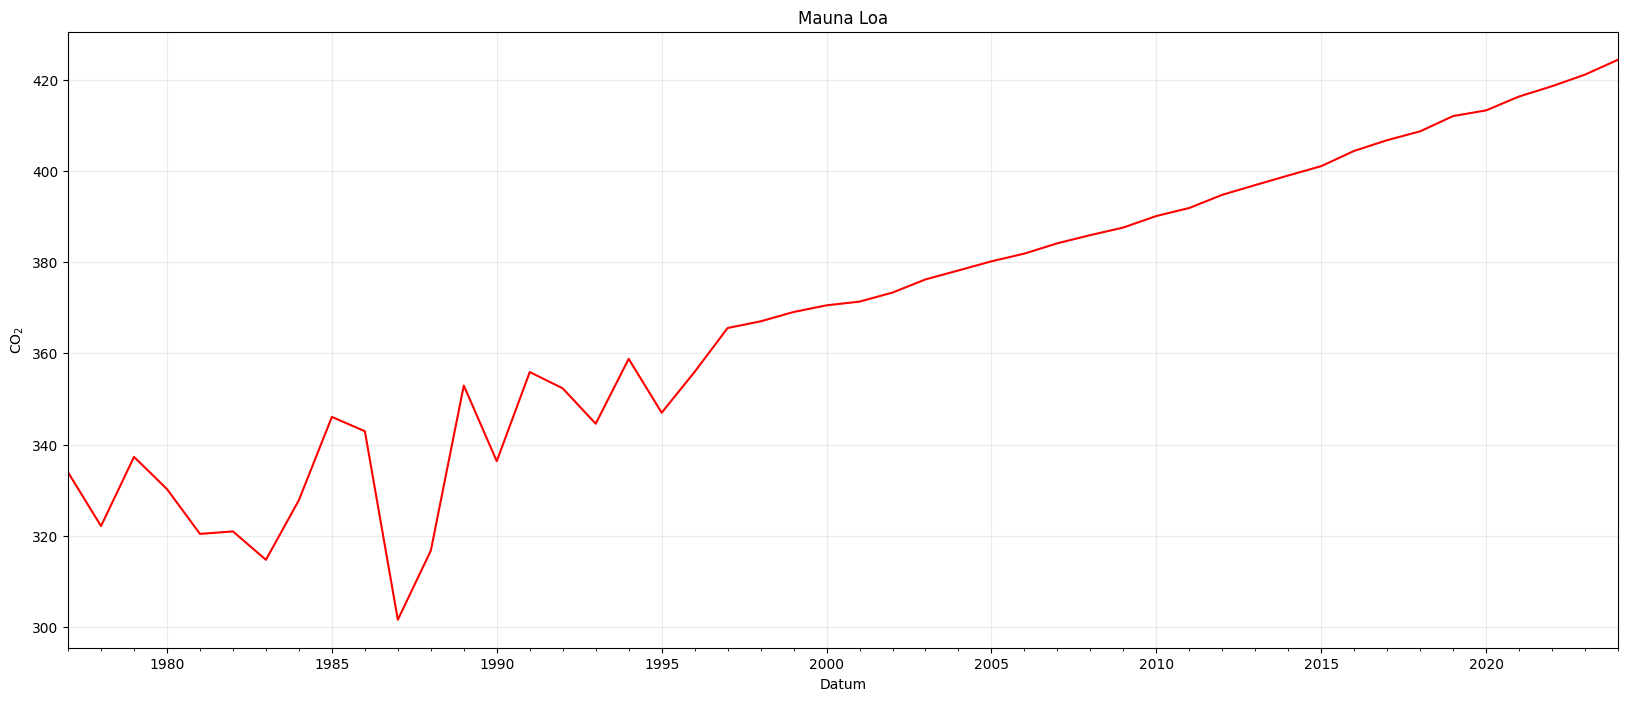

Global:


,count,mean,std,min,25%,50%,75%,max
value,48.0,368.933982,32.975589,301.571276,344.15118,370.93842,395.312648,424.4028


Pro Jahrzehnt:


value                                                             \
         count        mean        std         min         25%         50%   
datetime                                                                    
1970       3.0  331.096388   7.965449  322.108673  328.003273  333.897872   
1980      10.0  327.427544  15.922413  301.571276  317.638495  324.375441   
1990      10.0  355.247401  10.529278  336.345657  348.310938  355.919784   
2000      10.0  378.933915   6.045302  370.531458  374.050705  379.184441   
2010      10.0  400.567907   7.340600  390.121058  395.312648  400.035263   
2020       5.0  418.754858   4.280227  413.294242  416.337212  418.598871   

                                  
                 75%         max  
datetime                          
1970      335.590245  337.282617  
1980      339.749057  352.930143  
1990      363.866168  369.066078  
2000      383.574869  387.597547  
2010      406.169605  412.046226  
2020      421.141167  424.402800

Wachstumsrate in %:
	1980-1989: 0.7414
	2000-2009: 0.5016
	2010-2019: 0.6094
	2020-2024: 0.6653



In [ ]:
yearly = df.resample("YE").mean().dropna()

plt.figure(figsize=(20, 8))

yearly["value"].plot(color="red")

plt.title("Mauna Loa")
plt.xlabel("Datum")
plt.ylabel(r"CO$_2$")
plt.grid(alpha=0.25)
plt.margins(x=0)
plt.show()

print("Global:")
display(yearly.describe().transpose())
print("Pro Jahrzehnt:")
display(yearly.groupby((yearly.index.year // 10) * 10).describe())

rate = {"1980-1989": 0, "2000-2009": 0, "2010-2019": 0, "2020-2024": 0}

for index, year in enumerate([(1980, 1989), (2000, 2009), (2010, 2019), (2020, 2024)]):
    start = yearly[yearly.index.year == year[0]].iloc[0, 0]
    end = yearly[yearly.index.year == year[1]].iloc[0, 0]
    rate[list(rate.keys())[index]] = round(float((end / start) ** (1 / (year[1] - year[0])) - 1) * 100, 4)

print("Jährliche Wachstumsrate in %:")
string = ""
for key, val in rate.items():
    string = string + f"\t{key}: {val}\n"
print(string)

In [6]:
# TODO

# Aufgabe 2

In [7]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [8]:
df = pd.read_csv("FreiburgNiederschlag.csv")
df["category"] = pd.to_datetime(df["category"], format="mixed")
df = df.rename(columns={"category": "date", "Niederschlag": "value"})
df = df.set_index("date").sort_index()

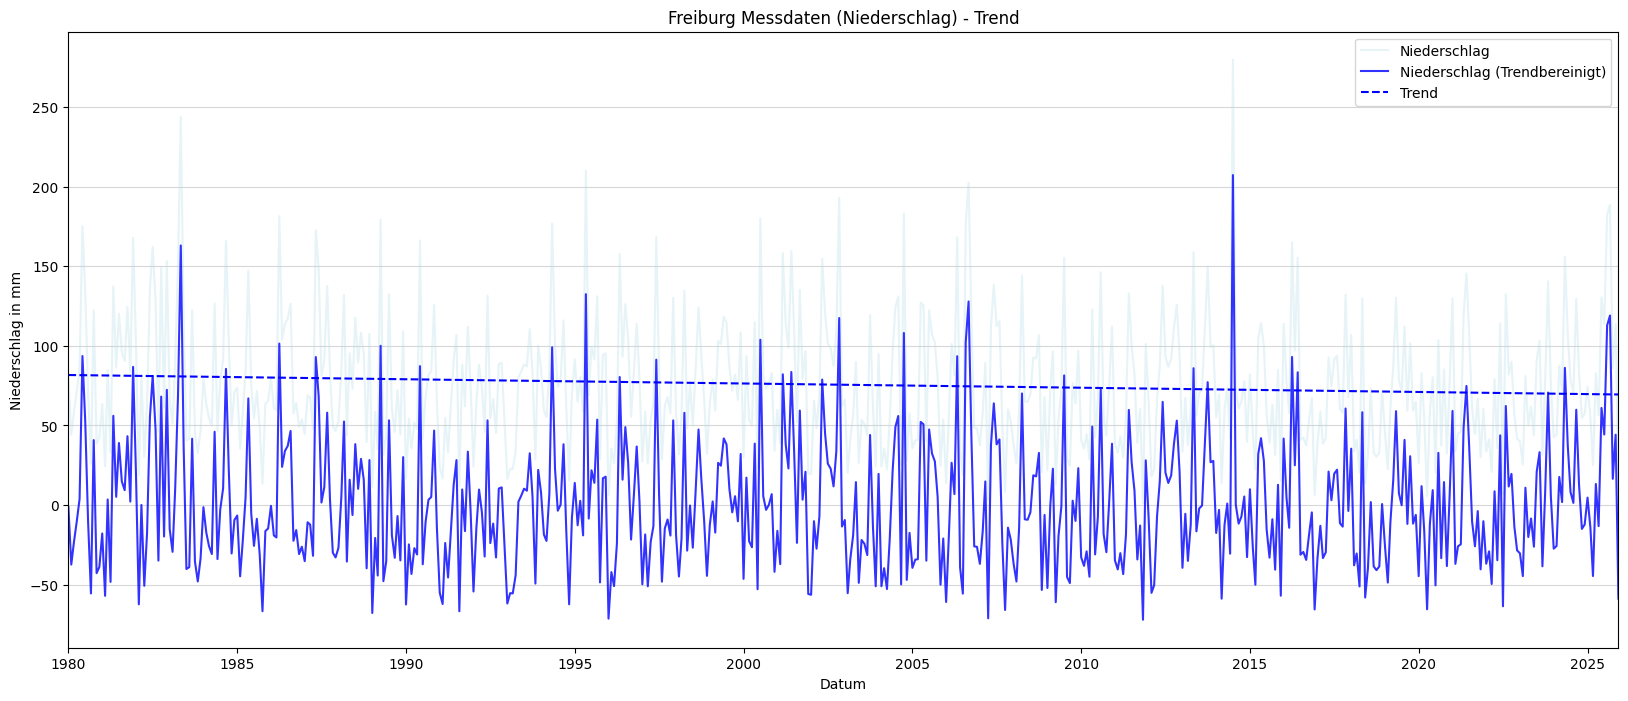

In [9]:
# Trend
x = mdates.date2num(df.index)
p = np.poly1d(np.polyfit(x, df["value"], 1))
df["trend"] = p(x)

df["detrended"] = df["value"] - df["trend"]

plt.figure(figsize=(20, 8))

plt.plot(df.index, df["value"], color="lightblue", alpha=0.3, label="Niederschlag")
plt.plot(df.index, df["detrended"], color="blue", alpha=0.8, label="Niederschlag (Trendbereinigt)")
plt.plot(df.index, df["trend"], color="blue", alpha=1, label="Trend", linestyle="--")

plt.title("Freiburg Messdaten (Niederschlag) - Trend")
plt.xlabel("Datum")
plt.ylabel("Niederschlag in mm")
plt.grid(axis="y", alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.show()

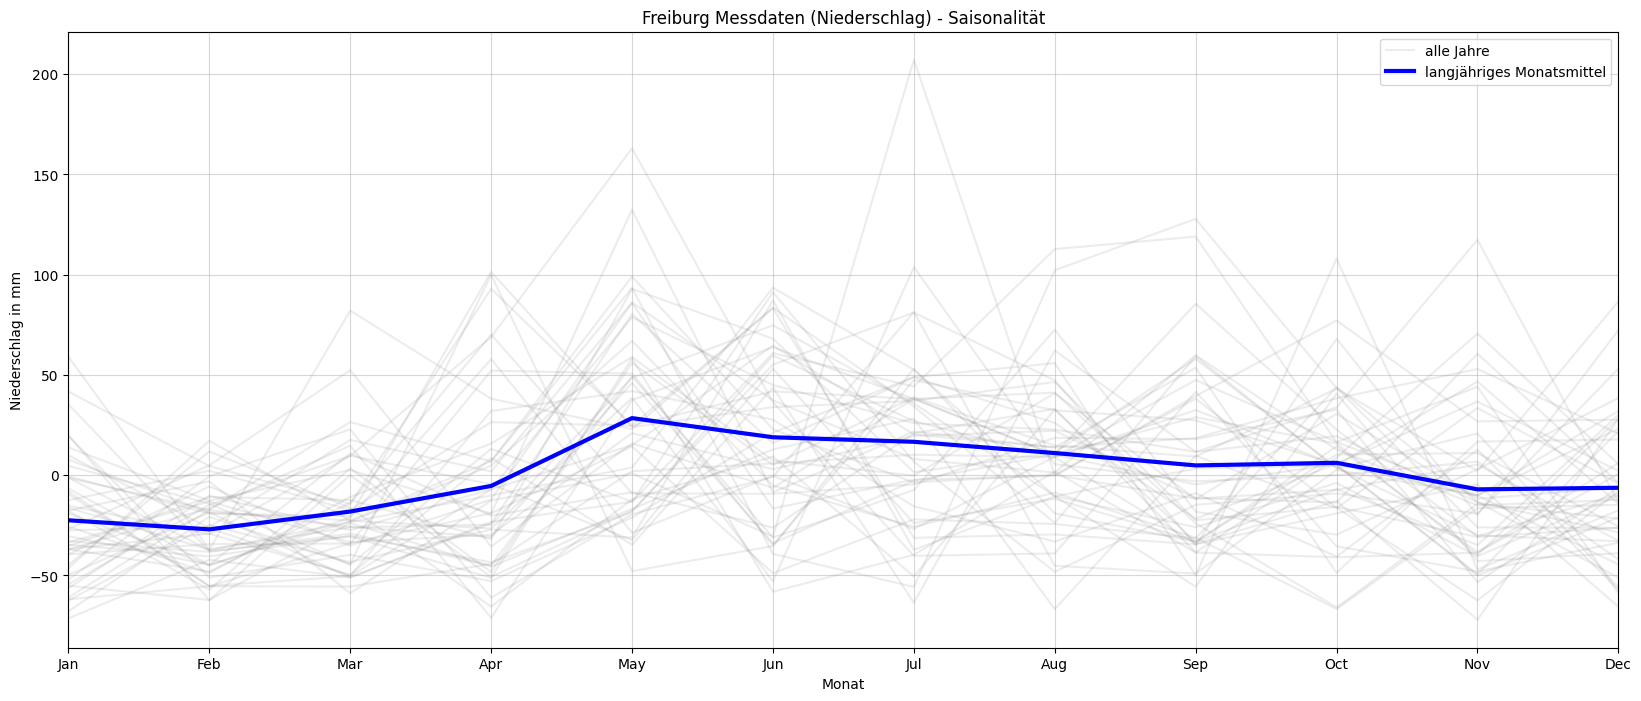

In [10]:
# Jährliche Saisonalität
df["month"] = df.index.month
df["year"] = df.index.year

seasonal = df.groupby("month")["detrended"].mean()

plt.figure(figsize=(20, 8))

for i, y in enumerate(df["year"].unique()):
    data = df[df["year"] == y]
    if i == 0:
        plt.plot(data["month"], data["detrended"], color="gray", alpha=0.15, label="alle Jahre")
    else:
        plt.plot(data["month"], data["detrended"], color="gray", alpha=0.15)
plt.plot(seasonal, color="blue", alpha=1, label="langjähriges Monatsmittel", linewidth=3)

plt.title("Freiburg Messdaten (Niederschlag) - Saisonalität")
plt.xlabel("Monat")
plt.ylabel("Niederschlag in mm")
plt.xticks(
    ticks=range(1, 13), labels=pd.Series(range(1, 13)).map(lambda x: pd.to_datetime(x, format="%m").strftime("%b"))
)
plt.grid(axis="both", alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.show()

df = df.join(seasonal, on="month", rsuffix="_seasonal")

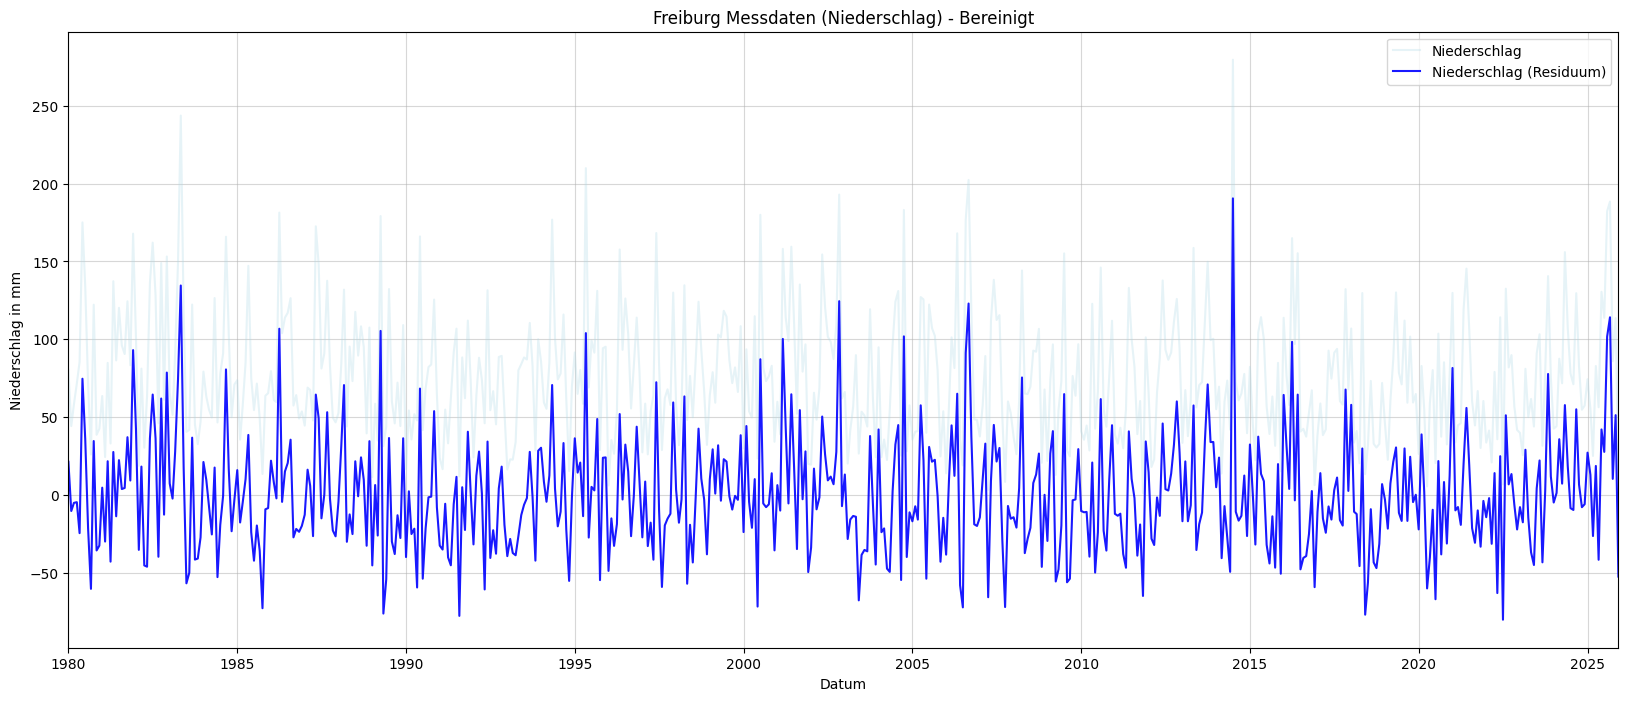

In [11]:
# Bereinigte Zeitreihe
df["resid"] = df["detrended"] - df["detrended_seasonal"]

plt.figure(figsize=(20, 8))

plt.plot(df.index, df["value"], color="lightblue", alpha=0.3, label="Niederschlag")
plt.plot(df.index, df["resid"], color="blue", alpha=0.9, label="Niederschlag (Residuum)")

plt.title("Freiburg Messdaten (Niederschlag) - Bereinigt")
plt.xlabel("Datum")
plt.ylabel("Niederschlag in mm")
plt.grid(axis="both", alpha=0.5)
plt.margins(x=0)
plt.legend()
plt.show()

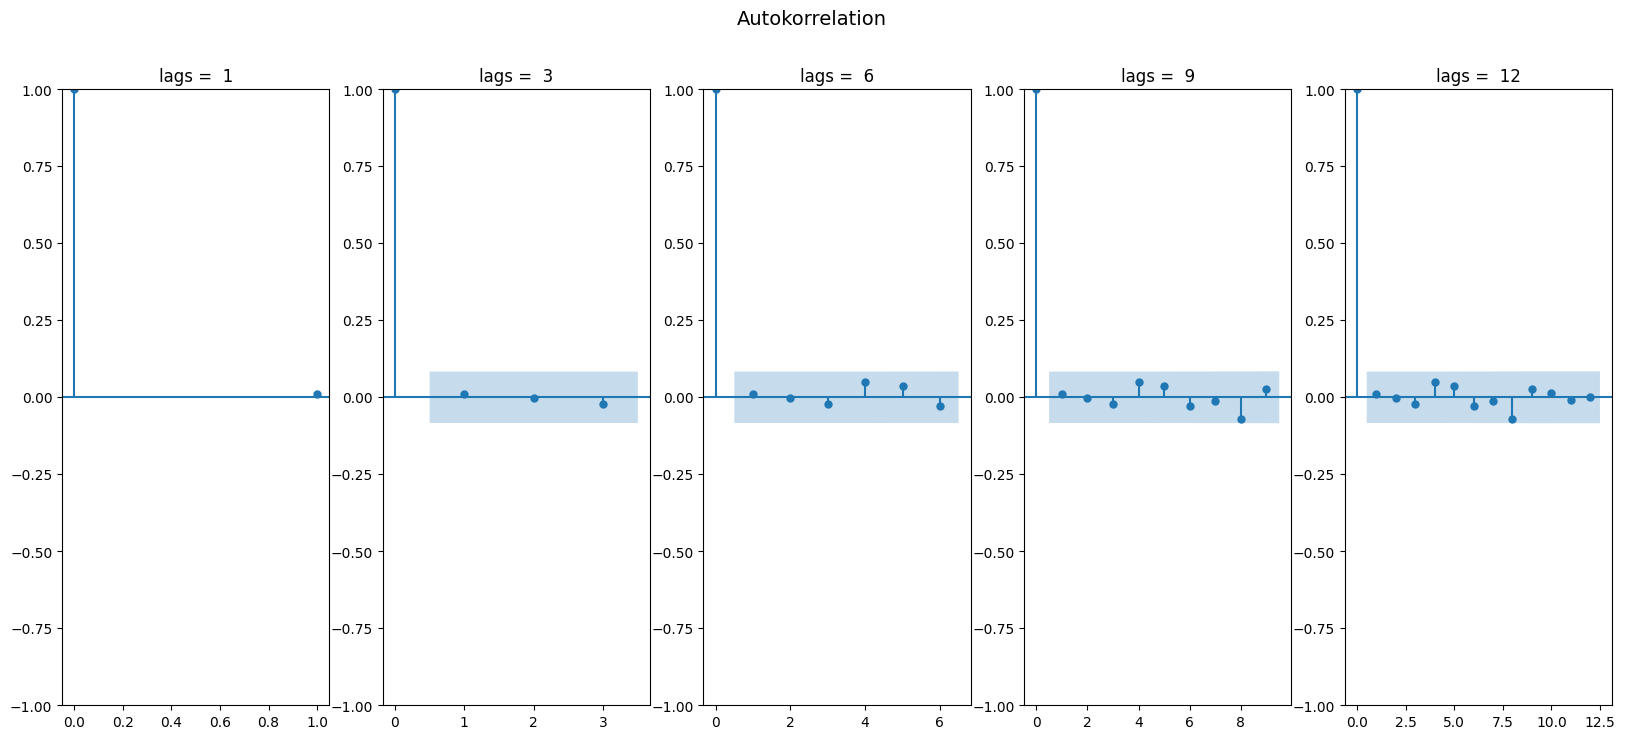

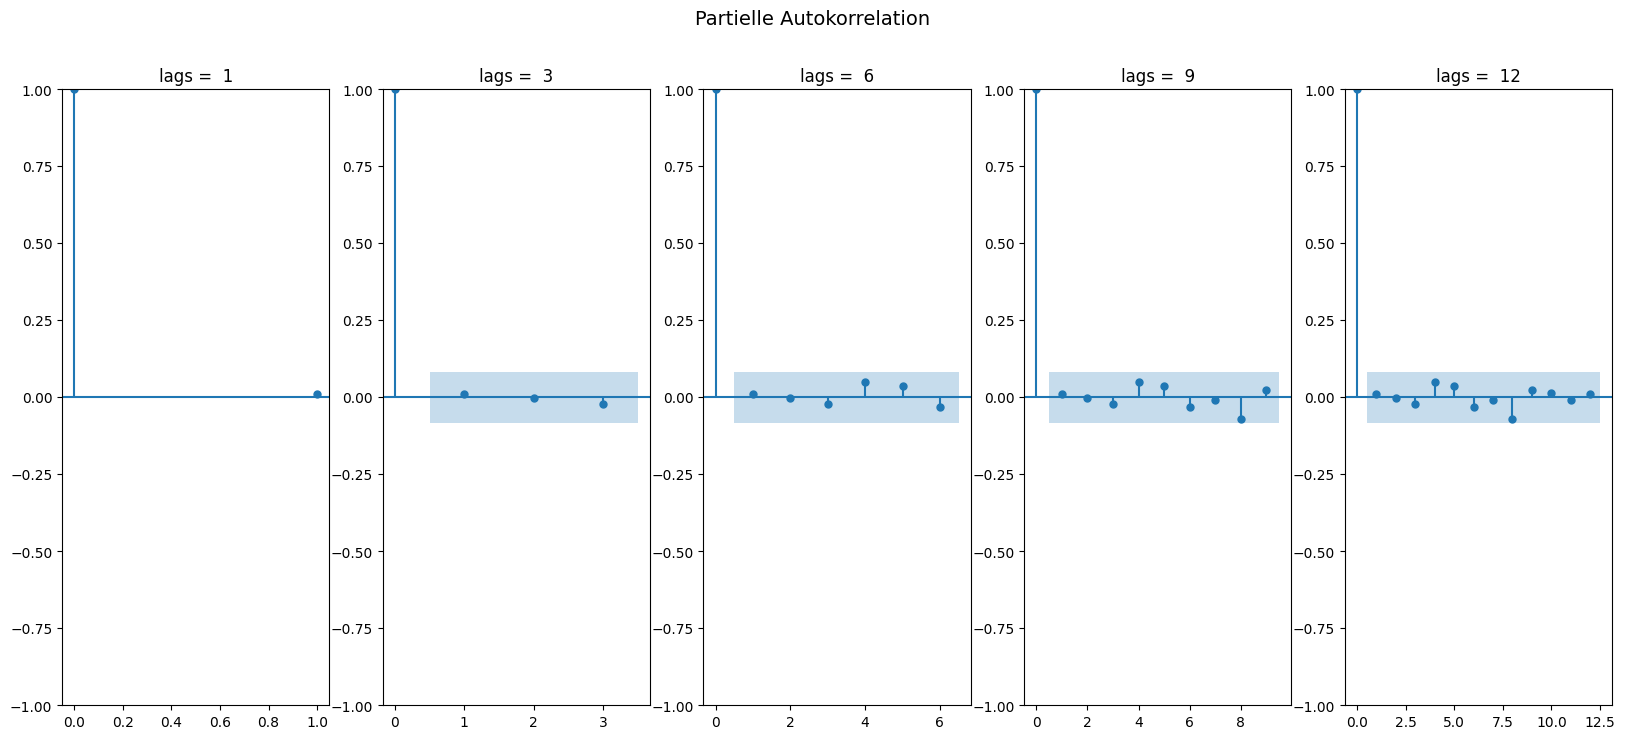

In [12]:
# Autokorrelation
lags = [1, 3, 6, 9, 12]

fig, ax = plt.subplots(1, len(lags), figsize=(20, 8))
for index, lag in enumerate(lags):
    plot_acf(df["resid"].dropna(), lags=lag, ax=ax[index])
    ax[index].set_title(f"lags =  {lag}")
fig.suptitle("Autokorrelation", fontsize=14)
plt.show()

fig, ax = plt.subplots(1, len(lags), figsize=(20, 8))
for index, lag in enumerate(lags):
    plot_pacf(df["resid"].dropna(), lags=lag, ax=ax[index])
    ax[index].set_title(f"lags =  {lag}")
fig.suptitle("Partielle Autokorrelation", fontsize=14)
plt.show()

In [13]:
# TODO